In [1]:
import pandas as pd

In [2]:
from matplotlib import pyplot as plt

In [3]:
import numpy as np

In [17]:
import seaborn as sns

In [7]:
df=pd.read_csv('diabetes_dataset.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [14]:
df.shape

(768, 9)

In [11]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [13]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [15]:
df.nunique()

Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64

In [18]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
(df==0).sum ()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [22]:
(df==0).mean()*100

Pregnancies                 14.453125
Glucose                      0.651042
BloodPressure                4.557292
SkinThickness               29.557292
Insulin                     48.697917
BMI                          1.432292
DiabetesPedigreeFunction     0.000000
Age                          0.000000
Outcome                     65.104167
dtype: float64

In [26]:
#replacing the 0 values with null 
cols=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
df[cols]=df[cols].replace(0,np.nan)

In [25]:
df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [28]:
(df.isnull().mean()*100).round(2)

Pregnancies                  0.00
Glucose                      0.65
BloodPressure                4.56
SkinThickness               29.56
Insulin                     48.70
BMI                          1.43
DiabetesPedigreeFunction     0.00
Age                          0.00
Outcome                      0.00
dtype: float64

In [29]:
df.shape

(768, 9)

In [31]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [33]:
df['Outcome'].value_counts(normalize=True)*100

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64

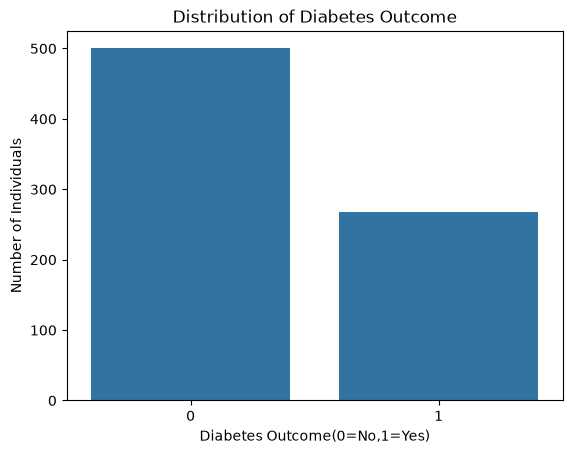

In [39]:
sns.countplot(x='Outcome',data=df)
plt.title('Distribution of Diabetes Outcome')
plt.xlabel('Diabetes Outcome(0=No,1=Yes)')
plt.ylabel('Number of Individuals')
plt.show()


In [41]:
#Analysing the glucose levels and diabetes outcomes
df.groupby('Outcome')['Glucose'].mean()

Outcome
0    110.643863
1    142.319549
Name: Glucose, dtype: float64

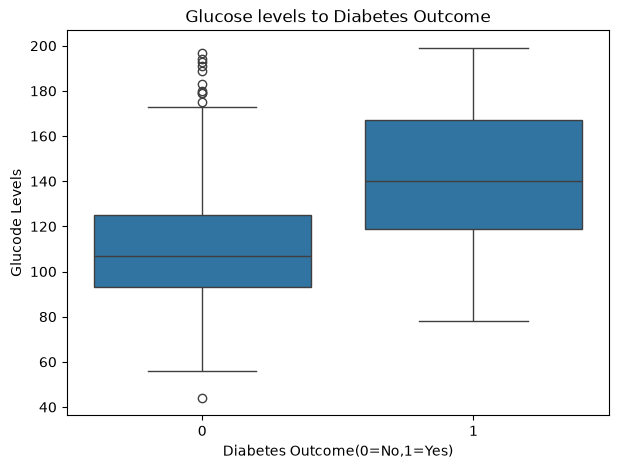

In [52]:
#Glucose vs Diabetes Outcome Graph
plt.figure(figsize=(7,5))
sns.boxplot(x='Outcome',y='Glucose',data=df)
plt.title('Glucose levels to Diabetes Outcome')
plt.xlabel('Diabetes Outcome(0=No,1=Yes)')
plt.ylabel('Glucode Levels')
plt.show()

### Observation: Glucose Levels and Diabetes Outcome

The boxplot illustrates the distribution of glucose levels among individuals with and without diabetes.

The median glucose level is noticeably higher in the diabetes group (Outcome 1) compared to the non-diabetes group (Outcome 0). Individuals without diabetes have a median glucose level of approximately 106, whereas individuals with diabetes have a median of approximately 140.

The visualisation suggests a positive association between higher glucose levels and diabetes outcomes in this dataset. However, the distributions overlap, indicating that glucose levels alone cannot explain every diabetes outcome.

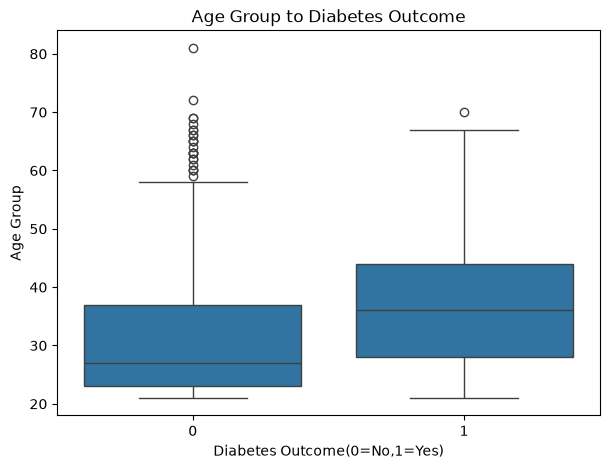

In [53]:
#Age vs Diabetes Outcome Graph
plt.figure(figsize=(7,5))
sns.boxplot(x='Outcome',y='Age',data=df)
plt.title('Age Group to Diabetes Outcome')
plt.xlabel('Diabetes Outcome(0=No,1=Yes)')
plt.ylabel('Age Group')
plt.show()

### Observation: Age and Diabetes Outcome

The boxplot compares the age distribution of individuals with and without diabetes. The median age of individuals with diabetes is approximately 36 years, compared to 27 years for individuals without diabetes.

The visualisation indicates that the diabetes group generally has an older age distribution. This suggests an association between age and diabetes outcomes within the dataset.

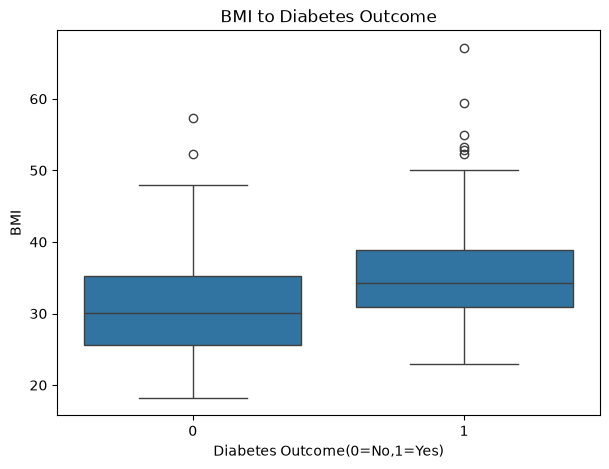

In [54]:
#BMI vs Diabetes Outcome Graph
plt.figure(figsize=(7,5))
sns.boxplot(x='Outcome',y='BMI',data=df)
plt.title('BMI to Diabetes Outcome')
plt.xlabel('Diabetes Outcome(0=No,1=Yes)')
plt.ylabel('BMI')
plt.show()

### Observation: BMI and Diabetes Outcome

The boxplot compares BMI distributions among individuals with and without diabetes. The median BMI of individuals with diabetes is approximately 34, compared to 30 among individuals without diabetes.

The diabetes group generally shows higher BMI values, suggesting an association between BMI and diabetes outcomes in the dataset. Some potential high-BMI outliers are also visible in both groups.

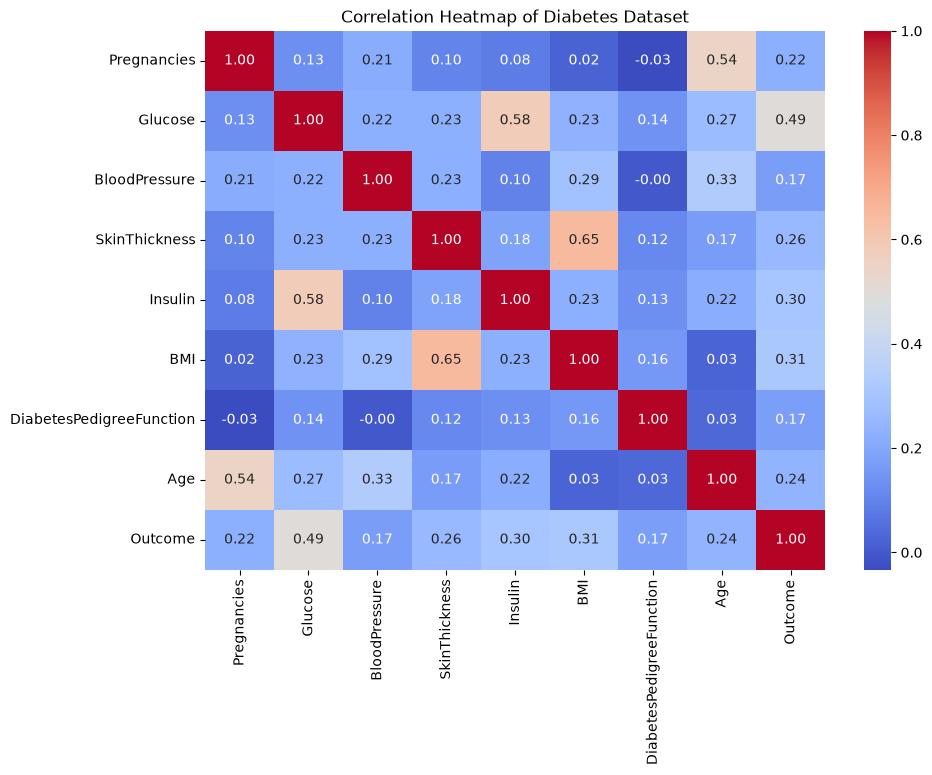

In [48]:
plt.figure(figsize=(10,7))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Diabetes Dataset')

plt.show()

### Observation: Correlation Analysis

The correlation heatmap illustrates the relationships between different variables in the diabetes dataset.

Glucose has the strongest positive correlation with diabetes outcome (0.49), followed by BMI (0.31) and Insulin (0.30). This indicates that these variables have relatively stronger positive associations with diabetes outcomes compared to the other variables.

Age (0.24) and Pregnancies (0.22) also show positive correlations with the outcome.

Additionally, SkinThickness and BMI have a correlation of 0.65, while Glucose and Insulin have a correlation of 0.58.

Overall, the heatmap highlights Glucose as the variable with the strongest correlation with diabetes outcome in this dataset. However, correlation does not establish causation.

In [50]:
df.groupby('Outcome')['Pregnancies'].mean()

Outcome
0    3.298000
1    4.865672
Name: Pregnancies, dtype: float64

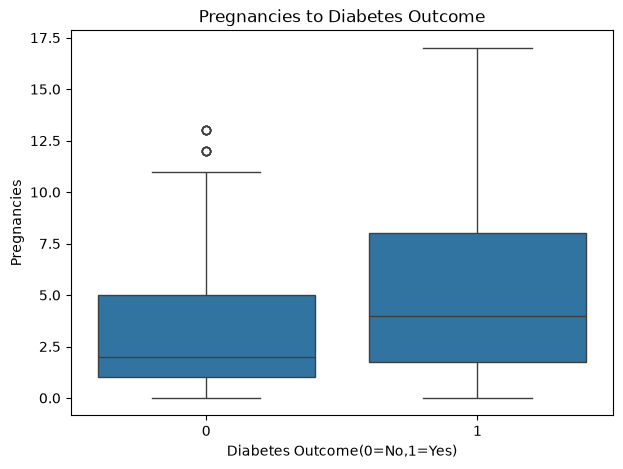

In [51]:
plt.figure(figsize=(7,5))
sns.boxplot(x='Outcome',y='Pregnancies',data=df)
plt.title('Pregnancies to Diabetes Outcome')
plt.xlabel('Diabetes Outcome(0=No,1=Yes)')
plt.ylabel('Pregnancies')
plt.show()

### Observation: Pregnancies and Diabetes Outcome

The boxplot compares the number of pregnancies among individuals with and without diabetes. The median number of pregnancies is approximately 4 in the diabetes group, compared to 2 in the non-diabetes group.

The diabetes group generally shows a higher number of pregnancies and a wider distribution. This suggests an association between the number of pregnancies and diabetes outcomes within the dataset.

## Key Findings

Based on the exploratory data analysis and visualisations, the following observations were identified:

**1. Diabetes Outcome Distribution**

The dataset contains 768 individuals, of whom 500 (65.1%) belong to the non-diabetes group and 268 (34.9%) belong to the diabetes group.

**2. Glucose Levels**

Individuals with diabetes show a noticeably higher median glucose level compared to individuals without diabetes. Glucose also has the strongest positive correlation with diabetes outcome (0.49).

**3. Age Distribution**

The median age of individuals with diabetes is approximately 36 years, compared to 27 years among individuals without diabetes. This indicates an older age distribution in the diabetes group.

**4. BMI Analysis**

The diabetes group has a higher median BMI (approximately 34) compared to the non-diabetes group (approximately 30).

**5. Correlation Analysis**

Glucose (0.49), BMI (0.31) and Insulin (0.30) show the strongest positive correlations with diabetes outcome among the variables analysed.

**6. Pregnancies Analysis**

Individuals in the diabetes group have a higher median number of pregnancies (approximately 4) compared to the non-diabetes group (approximately 2).

# Conclusion

This exploratory data analysis of the diabetes dataset helped identify patterns and relationships between various health-related factors and diabetes outcomes.

The analysis revealed that glucose levels have the strongest positive correlation with diabetes outcome, followed by BMI and insulin. The visualisations also showed that individuals in the diabetes group generally have higher glucose levels, BMI, age and number of pregnancies compared to the non-diabetes group.

The correlation heatmap provided an overall understanding of the relationships between the numerical variables. These findings highlight the importance of exploring multiple health indicators when studying patterns associated with diabetes.

Overall, this project provided practical experience in data handling, exploratory data analysis, statistical summaries and data visualisation using Python libraries such as Pandas, Matplotlib and Seaborn.